# 06. Avaliação dos Modelos com as Métricas de Desempenho (Aula 08)
**Disciplina:** DCT1401 - Inteligência Artificial (Aula 08 - Avaliação de Modelos de IA)  
**Dataset:** Food Delivery Orders and ETA Logistics Dataset  

Este notebook consolida a avaliação de todas as **3 famílias de modelos** (**Sistema Especialista**, **Árvore de Decisão** e **Ensembles: Random Forest & Gradient Boosting**) utilizando rigorosamente a taxonomia e as equações apresentadas pelo Prof. Dr. Thommas K. S. Flores na **Aula 08** e exigidas na **Seção 5.1 de `main-15.pdf`**:

### 1. Fórmulas e Propriedades das Métricas de Regressão (Aula 08, Seção 3)
Dado o erro residual $e_i = y_i - \hat{y}_i$ para $n$ observações:
- **Erro Médio Absoluto ($\text{MAE} = \frac{1}{n}\sum_{i=1}^n |y_i - \hat{y}_i|$):** Expresso em minutos; robusto a *outliers*, mas penaliza linearmente pequenos e grandes desvios.
- **Erro Quadrático Médio ($\text{MSE} = \frac{1}{n}\sum_{i=1}^n (y_i - \hat{y}_i)^2$):** Penaliza quadraticamente desvios graves, porém com unidade ao quadrado ($\text{min}^2$).
- **Raiz do Erro Quadrático Médio ($\text{RMSE} = \sqrt{\text{MSE}}$):** Mantém a penalização severa a grandes atrasos retornando à escala original em **minutos**.
- **Erro Percentual Absoluto Médio ($\text{MAPE} = \frac{100\%}{n}\sum_{i=1}^n \left|\frac{y_i - \hat{y}_i}{y_i}\right|$):** Facilita a comunicação executiva em porcentagem.
- **Coeficiente de Determinação ($R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$):** Adimensional; mede a proporção da variância total do tempo de entrega explicada pelo modelo.
- **Mediana do Erro Absoluto ($\text{MedAE} = \text{mediana}(|y_1 - \hat{y}_1|, \dots, |y_n - \hat{y}_n|)$):** Extremamente resistente a valores discrepantes (mede o erro típico central).

### 2. Fórmulas e Propriedades das Métricas de Classificação (Aula 08, Seção 4)
A partir da **Matriz de Confusão** ($\text{TN}, \text{FP}, \text{FN}, \text{TP}$):
- **$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$:** Proporção global de acertos (pode ser enganosa sob desbalanceamento de classes).
- **$\text{Precision} = \frac{TP}{TP + FP}$:** Entre os pedidos que o modelo alertou como atrasados, qual fração realmente atrasou? (Controla os **Falsos Positivos / Falsos Alarmes**).
- **$\text{Recall (Sensibilidade)} = \frac{TP}{TP + FN}$:** Entre todos os pedidos que realmente atrasaram, quantos o modelo conseguiu detectar? (Controla os **Falsos Negativos / Atrasos Surpresa**).
- **$\text{F1-score} = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$:** Média harmônica entre Precisão e Recall; métrica ideal para conjuntos desbalanceados.
- **$\text{ROC-AUC}$ e $\text{PR-AUC}$:** Áreas sob as curvas ROC ($\text{TPR}$ vs. $\text{FPR}$) e Precision-Recall em todos os limiares (*thresholds*) de decisão.


## 1. Validação do Módulo `src/metrics.py` com o Exemplo Resolvido da Aula 08 (Páginas 2 e 3)
Antes de avaliar os modelos no dataset de delivery, validamos nossa função `compute_regression_metrics` aplicando-a exatamente às listas $y = \{10, 20, 30, 40, 50\}$ e $\hat{y} = \{12, 18, 33, 37, 52\}$ da **Aula 08 (Seção 3, Página 3)**.

In [1]:
from IPython.display import display
import os
import sys
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=UserWarning)

sys.path.append("..")
from src.metrics import compute_regression_metrics, compute_classification_metrics
from src.visualization import (
    plot_confusion_matrix_fig,
    plot_all_confusion_matrices,
    plot_roc_curves,
    plot_precision_recall_curves,
    plot_residuals
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

# Teste exato do exemplo da Aula 08 (páginas 2 e 3):
y_aula08 = np.array([10, 20, 30, 40, 50])
y_hat_aula08 = np.array([12, 18, 33, 37, 52])
exemplo_aula08 = compute_regression_metrics(y_aula08, y_hat_aula08)
print("=== VALIDAÇÃO DO EXEMPLO DA AULA 08 (y = [10,20,30,40,50], y_hat = [12,18,33,37,52]) ===")
print(f"MAE: {exemplo_aula08['MAE']:.4f} | MSE: {exemplo_aula08['MSE']:.4f} | RMSE: {exemplo_aula08['RMSE']:.4f} | "
      f"MAPE: {exemplo_aula08['MAPE_%']:.2f}% | R²: {exemplo_aula08['R2']:.4f} | MedAE: {exemplo_aula08['MedAE']:.4f}")


=== VALIDAÇÃO DO EXEMPLO DA AULA 08 (y = [10,20,30,40,50], y_hat = [12,18,33,37,52]) ===
MAE: 2.4000 | MSE: 6.0000 | RMSE: 2.4495 | MAPE: 10.30% | R²: 0.9700 | MedAE: 2.0000


## 2. Carregamento dos Dados e dos Modelos das Três Famílias
Carregamos os conjuntos de treino e teste (idênticos para todos os modelos) e os modelos ajustados nos Notebooks 03, 04 e 05.

In [2]:
df_clf = pd.read_csv("../data/processed/dataset_classification.csv")
df_reg = pd.read_csv("../data/processed/dataset_regression.csv")

X_clf = df_clf.drop(columns=["late_delivery"])
y_clf = df_clf["late_delivery"]
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

X_reg = df_reg.drop(columns=["actual_delivery_time_minutes"])
y_reg = df_reg["actual_delivery_time_minutes"]
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=42
)

# Carregamento dos modelos salvos
exp_clf = joblib.load("../models/expert_system_clf.pkl")
dt_clf = joblib.load("../models/decision_tree_clf.pkl")
rf_clf = joblib.load("../models/random_forest_clf.pkl")
gb_clf = joblib.load("../models/gradient_boosting_clf.pkl")

exp_reg = joblib.load("../models/expert_system_reg.pkl")
dt_reg = joblib.load("../models/decision_tree_reg.pkl")
rf_reg = joblib.load("../models/random_forest_reg.pkl")
gb_reg = joblib.load("../models/gradient_boosting_reg.pkl")

modelos_clf = {
    "Sistema Especialista (Regras SE-ENTÃO)": ("Sistema Especialista", exp_clf),
    "Árvore de Decisão (DecisionTreeClassifier)": ("Árvore de Decisão", dt_clf),
    "Random Forest (RandomForestClassifier)": ("Ensemble (Bagging)", rf_clf),
    "Gradient Boosting (GradientBoostingClassifier)": ("Ensemble (Boosting)", gb_clf),
}

modelos_reg = {
    "Sistema Especialista (Regras SE-ENTÃO)": ("Sistema Especialista", exp_reg),
    "Árvore de Decisão (DecisionTreeRegressor)": ("Árvore de Decisão", dt_reg),
    "Random Forest (RandomForestRegressor)": ("Ensemble (Bagging)", rf_reg),
    "Gradient Boosting (GradientBoostingRegressor)": ("Ensemble (Boosting)", gb_reg),
}
print("Todos os 8 modelos (4 de Classificação e 4 de Regressão) carregados com sucesso!")


Todos os 8 modelos (4 de Classificação e 4 de Regressão) carregados com sucesso!


## 3. Tabelas Comparativas Lado a Lado: Regressão e Classificação (Treino e Teste)
Calculamos todas as métricas obrigatórias da Aula 08 para cada modelo no **conjunto de teste** e no **conjunto de treino**, exportando as tabelas comparativas para `../reports/tables/`.

In [3]:
# 1. Avaliação Lado a Lado - REGRESSÃO
linhas_reg = []
preds_test_reg = {}

for nome, (familia, mod) in modelos_reg.items():
    p_tr = mod.predict(X_train_reg)
    p_te = mod.predict(X_test_reg)
    preds_test_reg[nome] = p_te

    m_tr = compute_regression_metrics(y_train_reg, p_tr)
    m_te = compute_regression_metrics(y_test_reg, p_te)

    linhas_reg.append({
        "Familia": familia,
        "Modelo": nome,
        "Particao": "Treino (80%)",
        "MAE (min)": m_tr["MAE"],
        "MSE (min²)": m_tr["MSE"],
        "RMSE (min)": m_tr["RMSE"],
        "MAPE (%)": m_tr["MAPE_%"],
        "R2": m_tr["R2"],
        "MedAE (min)": m_tr["MedAE"]
    })
    linhas_reg.append({
        "Familia": familia,
        "Modelo": nome,
        "Particao": "Teste (20%)",
        "MAE (min)": m_te["MAE"],
        "MSE (min²)": m_te["MSE"],
        "RMSE (min)": m_te["RMSE"],
        "MAPE (%)": m_te["MAPE_%"],
        "R2": m_te["R2"],
        "MedAE (min)": m_te["MedAE"]
    })

df_eval_reg = pd.DataFrame(linhas_reg)
df_eval_reg_teste = df_eval_reg[df_eval_reg["Particao"] == "Teste (20%)"].reset_index(drop=True)
df_eval_reg.to_csv("../reports/tables/evaluation_regression_full.csv", index=False)
df_eval_reg_teste.to_csv("../reports/tables/evaluation_regression_test.csv", index=False)

print("=== TABELA COMPARATIVA LADO A LADO - REGRESSÃO (CONJUNTO DE TESTE) ===")
display(df_eval_reg_teste)

print("\n=== TABELA COMPLETA - REGRESSÃO (TREINO E TESTE) ===")
display(df_eval_reg)


=== TABELA COMPARATIVA LADO A LADO - REGRESSÃO (CONJUNTO DE TESTE) ===


,Familia,Modelo,Particao,MAE (min),MSE (min²),RMSE (min),MAPE (%),R2,MedAE (min)
0,Sistema Especialista,Sistema Especialista (Regras SE-ENTÃO),Teste (20%),3.7587,22.9555,4.7912,12.38,0.8949,3.3000
1,Árvore de Decisão,Árvore de Decisão (DecisionTreeRegressor),Teste (20%),2.7625,12.4854,3.5335,8.78,0.9428,2.2500
2,Ensemble (Bagging),Random Forest (RandomForestRegressor),Teste (20%),2.3593,8.9755,2.9959,7.63,0.9589,1.9820
3,Ensemble (Boosting),Gradient Boosting (GradientBoostingRegressor),Teste (20%),2.1563,7.2903,2.7001,7.11,0.9666,1.8192



=== TABELA COMPLETA - REGRESSÃO (TREINO E TESTE) ===


,Familia,Modelo,Particao,MAE (min),MSE (min²),RMSE (min),MAPE (%),R2,MedAE (min)
0,Sistema Especialista,Sistema Especialista (Regras SE-ENTÃO),Treino (80%),3.7499,22.4514,4.7383,12.51,0.8948,3.3000
1,Sistema Especialista,Sistema Especialista (Regras SE-ENTÃO),Teste (20%),3.7587,22.9555,4.7912,12.38,0.8949,3.3000
2,Árvore de Decisão,Árvore de Decisão (DecisionTreeRegressor),Treino (80%),2.2751,8.3502,2.8897,7.40,0.9609,1.9000
3,Árvore de Decisão,Árvore de Decisão (DecisionTreeRegressor),Teste (20%),2.7625,12.4854,3.5335,8.78,0.9428,2.2500
4,Ensemble (Bagging),Random Forest (RandomForestRegressor),Treino (80%),1.6257,4.3659,2.0895,5.29,0.9795,1.3302
5,Ensemble (Bagging),Random Forest (RandomForestRegressor),Teste (20%),2.3593,8.9755,2.9959,7.63,0.9589,1.9820
6,Ensemble (Boosting),Gradient Boosting (GradientBoostingRegressor),Treino (80%),2.0463,6.5898,2.5671,6.81,0.9691,1.7272
7,Ensemble (Boosting),Gradient Boosting (GradientBoostingRegressor),Teste (20%),2.1563,7.2903,2.7001,7.11,0.9666,1.8192


In [4]:
# 2. Avaliação Lado a Lado - CLASSIFICAÇÃO
linhas_clf = []
preds_test_clf = {}
probs_test_clf = {}

for nome, (familia, mod) in modelos_clf.items():
    p_tr = mod.predict(X_train_clf)
    prob_tr = mod.predict_proba(X_train_clf)[:, 1] if hasattr(mod, "predict_proba") else None

    p_te = mod.predict(X_test_clf)
    prob_te = mod.predict_proba(X_test_clf)[:, 1] if hasattr(mod, "predict_proba") else None

    preds_test_clf[nome] = p_te
    probs_test_clf[nome] = (mod, prob_te)

    m_tr = compute_classification_metrics(y_train_clf, p_tr, prob_tr)
    m_te = compute_classification_metrics(y_test_clf, p_te, prob_te)

    linhas_clf.append({
        "Familia": familia,
        "Modelo": nome,
        "Particao": "Treino (80%)",
        "Accuracy": m_tr["Accuracy"],
        "Precision": m_tr["Precision"],
        "Recall": m_tr["Recall"],
        "F1-score": m_tr["F1-score"],
        "ROC-AUC": m_tr["ROC-AUC"],
        "PR-AUC": m_tr["PR-AUC"],
        "TN": m_tr["TN"], "FP": m_tr["FP"], "FN": m_tr["FN"], "TP": m_tr["TP"]
    })
    linhas_clf.append({
        "Familia": familia,
        "Modelo": nome,
        "Particao": "Teste (20%)",
        "Accuracy": m_te["Accuracy"],
        "Precision": m_te["Precision"],
        "Recall": m_te["Recall"],
        "F1-score": m_te["F1-score"],
        "ROC-AUC": m_te["ROC-AUC"],
        "PR-AUC": m_te["PR-AUC"],
        "TN": m_te["TN"], "FP": m_te["FP"], "FN": m_te["FN"], "TP": m_te["TP"]
    })

df_eval_clf = pd.DataFrame(linhas_clf)
df_eval_clf_teste = df_eval_clf[df_eval_clf["Particao"] == "Teste (20%)"].reset_index(drop=True)
df_eval_clf.to_csv("../reports/tables/evaluation_classification_full.csv", index=False)
df_eval_clf_teste.to_csv("../reports/tables/evaluation_classification_test.csv", index=False)

print("=== TABELA COMPARATIVA LADO A LADO - CLASSIFICAÇÃO (CONJUNTO DE TESTE) ===")
display(df_eval_clf_teste)

print("\n=== TABELA COMPLETA - CLASSIFICAÇÃO (TREINO E TESTE) ===")
display(df_eval_clf)


=== TABELA COMPARATIVA LADO A LADO - CLASSIFICAÇÃO (CONJUNTO DE TESTE) ===


,Familia,Modelo,Particao,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Sistema Especialista,Sistema Especialista (Regras SE-ENTÃO),Teste (20%),0.6804,0.5466,0.7398,0.6287,0.7370,0.6713,4027,2206,935,2659
1,Árvore de Decisão,Árvore de Decisão (DecisionTreeClassifier),Teste (20%),0.8031,0.7465,0.6989,0.7219,0.8755,0.8115,5380,853,1082,2512
2,Ensemble (Bagging),Random Forest (RandomForestClassifier),Teste (20%),0.8287,0.7831,0.7354,0.7585,0.9006,0.8533,5501,732,951,2643
3,Ensemble (Boosting),Gradient Boosting (GradientBoostingClassifier),Teste (20%),0.8335,0.7943,0.7351,0.7636,0.9100,0.8673,5549,684,952,2642



=== TABELA COMPLETA - CLASSIFICAÇÃO (TREINO E TESTE) ===


,Familia,Modelo,Particao,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,TN,FP,FN,TP
0,Sistema Especialista,Sistema Especialista (Regras SE-ENTÃO),Treino (80%),0.6809,0.5472,0.7387,0.6287,0.7351,0.6709,16144,8787,3756,10618
1,Sistema Especialista,Sistema Especialista (Regras SE-ENTÃO),Teste (20%),0.6804,0.5466,0.7398,0.6287,0.7370,0.6713,4027,2206,935,2659
2,Árvore de Decisão,Árvore de Decisão (DecisionTreeClassifier),Treino (80%),0.8122,0.7672,0.6986,0.7313,0.8867,0.8286,21883,3048,4332,10042
3,Árvore de Decisão,Árvore de Decisão (DecisionTreeClassifier),Teste (20%),0.8031,0.7465,0.6989,0.7219,0.8755,0.8115,5380,853,1082,2512
4,Ensemble (Bagging),Random Forest (RandomForestClassifier),Treino (80%),0.9164,0.9182,0.8468,0.8810,0.9783,0.9660,23846,1085,2202,12172
5,Ensemble (Bagging),Random Forest (RandomForestClassifier),Teste (20%),0.8287,0.7831,0.7354,0.7585,0.9006,0.8533,5501,732,951,2643
6,Ensemble (Boosting),Gradient Boosting (GradientBoostingClassifier),Treino (80%),0.8487,0.8218,0.7487,0.7835,0.9244,0.8888,22597,2334,3612,10762
7,Ensemble (Boosting),Gradient Boosting (GradientBoostingClassifier),Teste (20%),0.8335,0.7943,0.7351,0.7636,0.9100,0.8673,5549,684,952,2642


## 4. Matrizes de Confusão, Curvas ROC e Curvas Precision-Recall
Gera e salva os gráficos diagnósticos de classificação para os 4 modelos:
1. **Matrizes de Confusão Lado a Lado (`confusion_matrices_all.png` e `confusion_matrix.png`):** Detalham $\text{TN}$ (pedidos no prazo previstos corretamente), $\text{FP}$ (falso alarme de atraso), $\text{FN}$ (atraso não previsto / surpresa negativa ao cliente) e $\text{TP}$ (atraso detectado com sucesso).
2. **Curvas ROC (`roc_curves.png`) e Precision-Recall (`pr_curves.png`):**
   - **Como obter (ou por que não há probabilidade nativa em) um Sistema Especialista?**
     Um sistema especialista simbólico puro baseado em lógica booleana (`SE-ENTÃO`) produz decisões determinísticas discretas ($0$ ou $1$), **não estimando probabilidades frequentistas contínuas** como as folhas de uma Árvore de Decisão ($p(Y=c|X=x) = n_{k,c}/n_k$) ou a média de probabilidades de um Ensemble. Para incluí-lo nas curvas ROC e PR como referência, associamos a cada regra um **Fator de Certeza (*Certainty Factor*)** empírico calibrado pela frequência relativa de atrasos observada no conjunto de treino quando aquela regra dispara (resultando em uma curva poligonal por partes, tracejada nos gráficos abaixo).

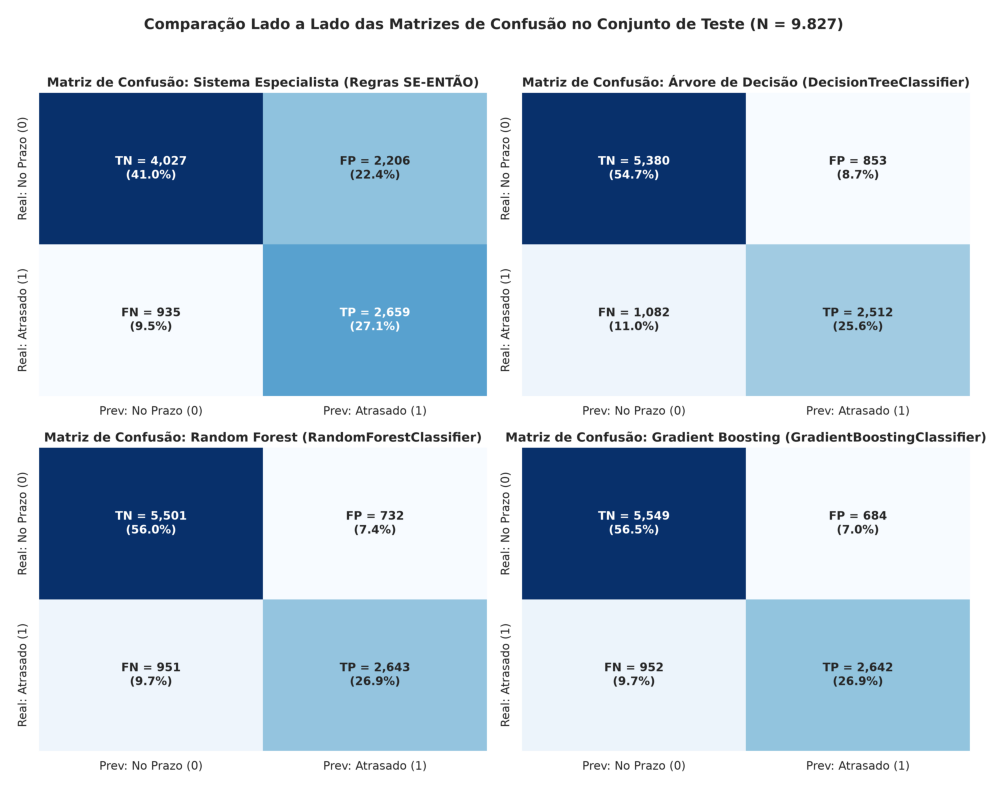

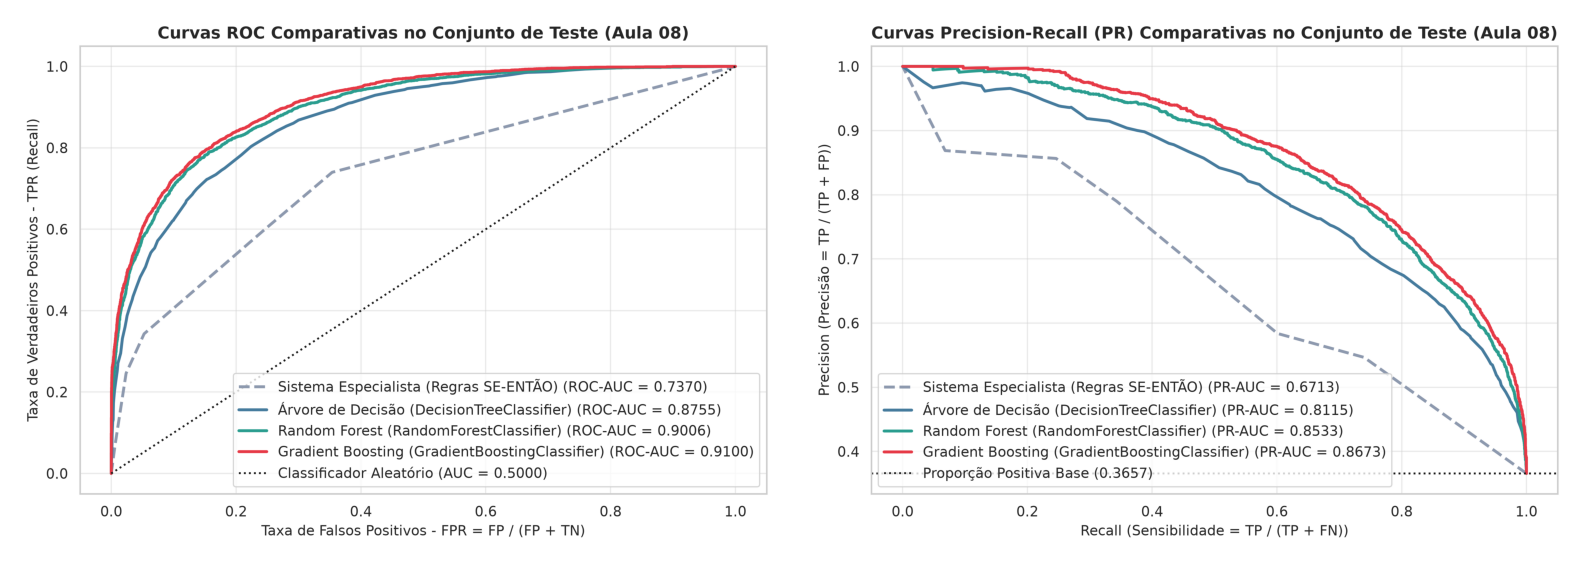

In [5]:
# 1. Painel 2x2 com as Matrizes de Confusão dos 4 modelos + Matriz do modelo campeão
plot_all_confusion_matrices(preds_test_clf, y_test_clf, filename="confusion_matrices_all.png")
plot_confusion_matrix_fig(
    y_test_clf,
    preds_test_clf["Gradient Boosting (GradientBoostingClassifier)"],
    model_name="Gradient Boosting (Campeão)",
    filename="confusion_matrix.png"
)

# Exibe o painel 2x2 de Matrizes de Confusão no notebook
img_cm = plt.imread("../reports/figures/confusion_matrices_all.png")
plt.figure(figsize=(13, 10))
plt.imshow(img_cm)
plt.axis("off")
plt.show()

# 2. Curvas ROC e Precision-Recall lado a lado
plot_roc_curves(probs_test_clf, X_test_clf, y_test_clf, filename="roc_curves.png")
plot_precision_recall_curves(probs_test_clf, X_test_clf, y_test_clf, filename="pr_curves.png")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(plt.imread("../reports/figures/roc_curves.png"))
axes[0].axis("off")
axes[1].imshow(plt.imread("../reports/figures/pr_curves.png"))
axes[1].axis("off")
plt.tight_layout()
plt.show()


## 5. Análise de Resíduos ($e_i = y_i - \hat{y}_i$) e Gráficos Real vs. Previsto na Regressão
Para diagnosticar o comportamento dos erros de regressão ao longo da faixa de tempo de entrega ($10$ a $120$ minutos), construímos:
1. **Painel de Gráficos Real vs. Previsto para os 4 Modelos (`regression_real_vs_pred_all.png`):** Quanto mais próximos os pontos estiverem da reta identidade $y = \hat{y}$, menor a dispersão do erro.
2. **Painel de Gráficos de Resíduos $e_i = y_i - \hat{y}_i$ vs. Valores Previstos $\hat{y}_i$ (`residuals_all_models.png`) e Distribuição dos Resíduos:** Permite verificar se os resíduos estão centrados em zero (ausência de viés sistemático) e se há heterocedasticidade.

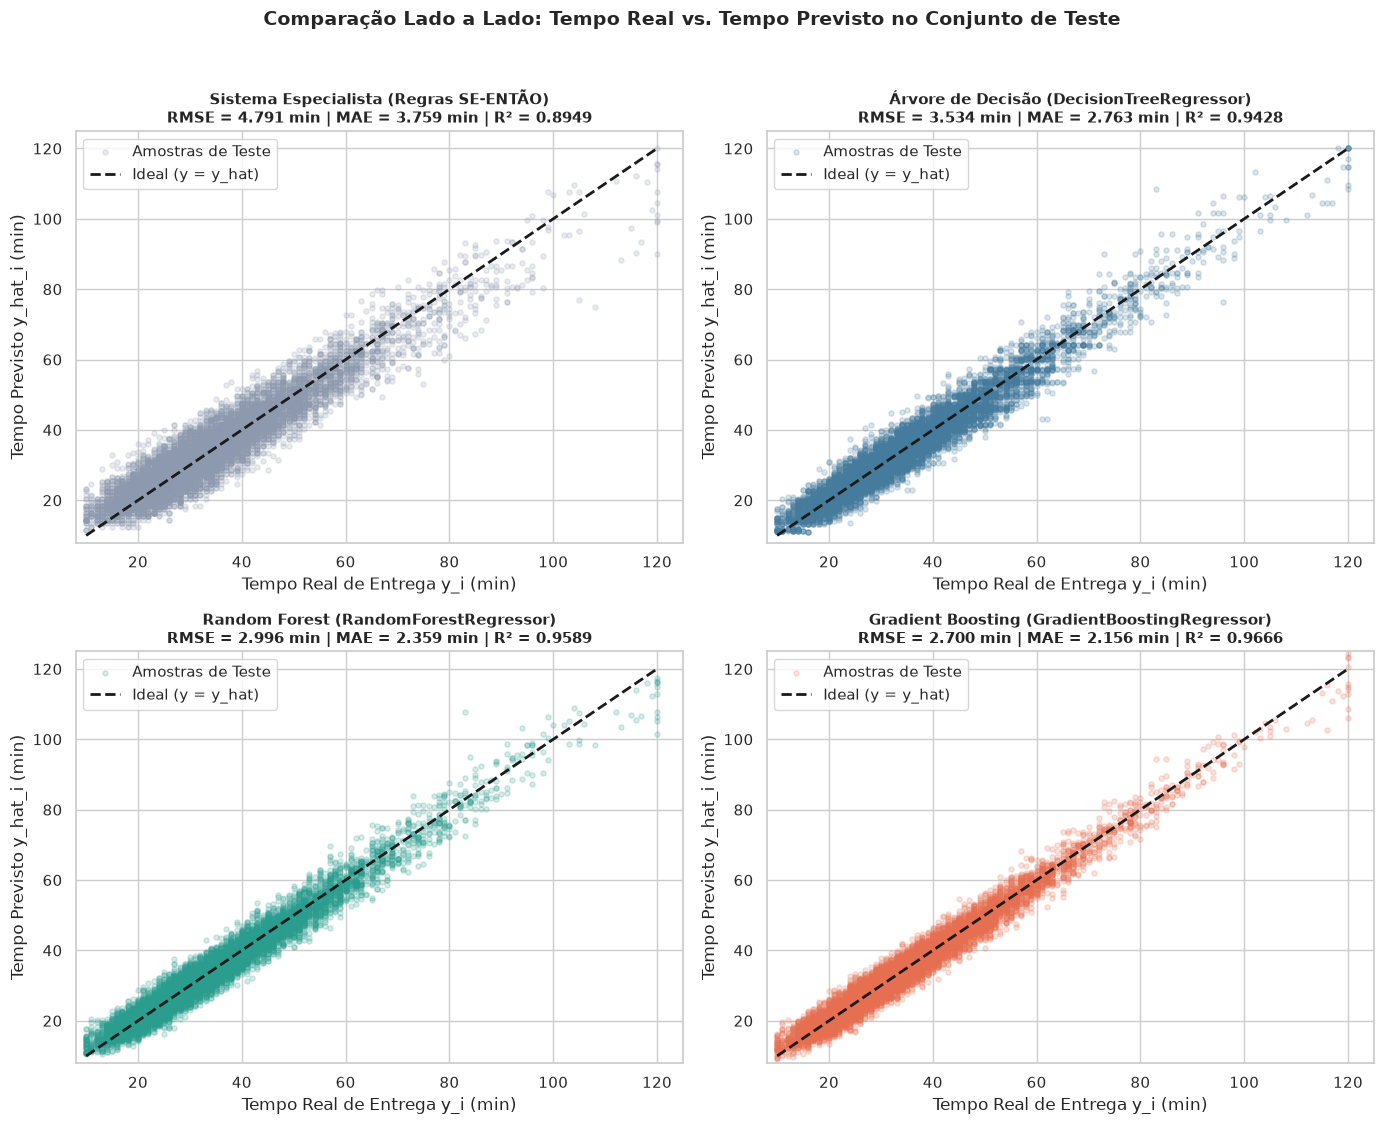

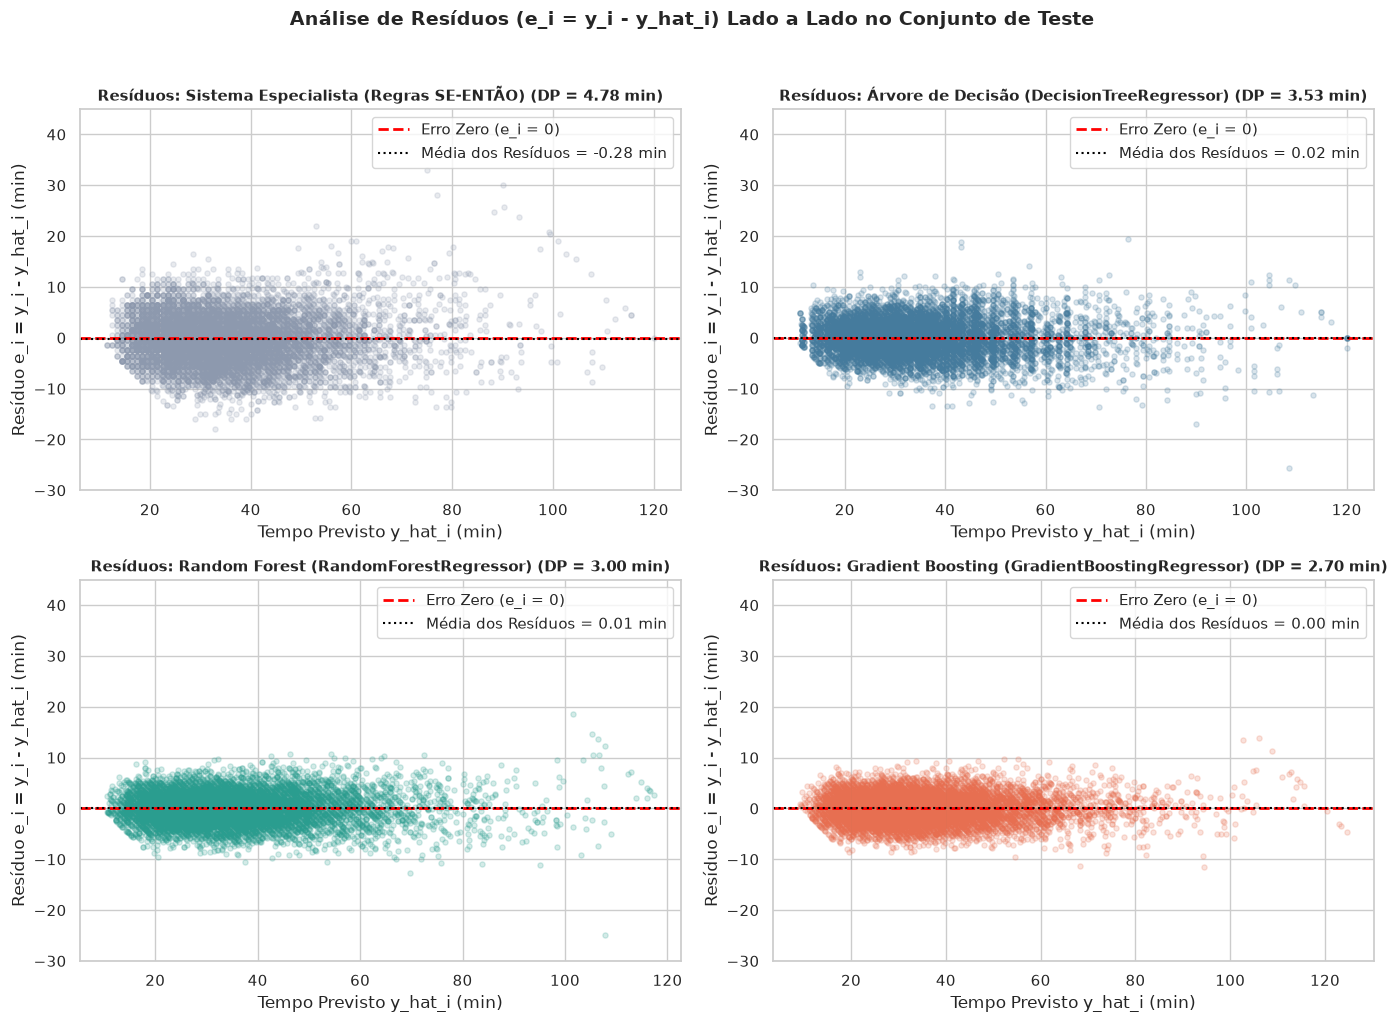

In [6]:
# Salva também o gráfico de resíduos individual do modelo campeão (residuals_plot.png)
plot_residuals(
    y_test_reg,
    preds_test_reg["Gradient Boosting (GradientBoostingRegressor)"],
    model_name="Gradient Boosting Regressor",
    filename="residuals_plot.png"
)

# 1. Painel 2x2: Real vs. Previsto para os 4 modelos
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
cores_reg = ["#8d99ae", "#457b9d", "#2a9d8f", "#e76f51"]

for ax, (nome, y_pred_m), cor in zip(axes.flatten(), preds_test_reg.items(), cores_reg):
    m = compute_regression_metrics(y_test_reg, y_pred_m)
    ax.scatter(y_test_reg, y_pred_m, alpha=0.20, color=cor, s=14, label="Amostras de Teste")
    ax.plot([10, 120], [10, 120], "k--", lw=2, label="Ideal (y = y_hat)")
    ax.set_title(f"{nome}\nRMSE = {m['RMSE']:.3f} min | MAE = {m['MAE']:.3f} min | R² = {m['R2']:.4f}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Tempo Real de Entrega y_i (min)")
    ax.set_ylabel("Tempo Previsto y_hat_i (min)")
    ax.set_xlim(8, 125)
    ax.set_ylim(8, 125)
    ax.legend(loc="upper left")

plt.suptitle("Comparação Lado a Lado: Tempo Real vs. Tempo Previsto no Conjunto de Teste", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/regression_real_vs_pred_all.png", dpi=300, bbox_inches="tight")
plt.show()

# 2. Painel 2x2: Gráficos de Resíduos (e_i = y_i - y_hat_i) para os 4 modelos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, (nome, y_pred_m), cor in zip(axes.flatten(), preds_test_reg.items(), cores_reg):
    residuos = y_test_reg - y_pred_m
    media_res = np.mean(residuos)
    dp_res = np.std(residuos)
    ax.scatter(y_pred_m, residuos, alpha=0.20, color=cor, s=14)
    ax.axhline(0.0, color="red", linestyle="--", lw=2, label="Erro Zero (e_i = 0)")
    ax.axhline(media_res, color="black", linestyle=":", lw=1.5, label=f"Média dos Resíduos = {media_res:.2f} min")
    ax.set_title(f"Resíduos: {nome} (DP = {dp_res:.2f} min)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Tempo Previsto y_hat_i (min)")
    ax.set_ylabel("Resíduo e_i = y_i - y_hat_i (min)")
    ax.set_ylim(-30, 45)
    ax.legend(loc="upper right")

plt.suptitle("Análise de Resíduos (e_i = y_i - y_hat_i) Lado a Lado no Conjunto de Teste", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("../reports/figures/residuals_all_models.png", dpi=300, bbox_inches="tight")
plt.show()


## 6. Discussão Crítica: Desbalanceamento de Classes, Custo de Erros e Escolha da Métrica Principal
Atendendo aos itens obrigatórios da **Seção 5.1 de `main-15.pdf`**:

### 6.1 Por que a *Accuracy* pode ser enganosa sob desbalanceamento e quais métricas são mais adequadas?
- No nosso dataset, $63{,}43\%$ dos pedidos chegam no prazo (Classe $0$) e $36{,}57\%$ sofrem atraso (Classe $1$). Um classificador trivial que simplesmente previsse *"Todos os pedidos chegarão no prazo"* obteria uma **Acurácia aparente de $63{,}43\%$**, mas teria $\text{Recall} = 0\%$ e $\text{F1-score} = 0$, falhando em detectar qualquer atraso real.
- Portanto, as métricas mais adequadas são o **F1-score** (que exige simultaneamente alta precisão e alta sensibilidade na classe minoritária de atrasos) e a **PR-AUC** (Área sob a Curva Precision-Recall, que foca especificamente no desempenho sobre a classe positiva $1$, sem ser inflada pelo grande volume de Verdadeiros Negativos $\text{TN}$).

### 6.2 Escolha da Métrica Principal para Classificação: Custo de Falsos Negativos ($\text{FN}$) vs. Falsos Positivos ($\text{FP}$)
- **Falso Negativo ($\text{FN}$ - Atraso Surpresa):** O modelo prevê que o pedido chegará no prazo, nenhuma ação preventiva é tomada, e a refeição chega atrasada. **Custo de negócio alto:** frustração severa do cliente, queda no `customer_rating`, solicitações de reembolso/cupom e perda de retenção (*churn*).
- **Falso Positivo ($\text{FP}$ - Falso Alarme):** O modelo prevê risco de atraso, o sistema ajusta preventivamente o aviso ou prioriza um entregador próximo, e o pedido chega no prazo. **Custo de negócio moderado/baixo.**
- **Decisão:** Adotamos o **F1-score** como métrica principal de classificação (pois equilibra `Precision` e `Recall`), utilizando o **Recall** e a **PR-AUC** como critérios de desempate. O **Gradient Boosting** vence na classificação por alcançar o maior **F1-score ($0{,}7636$)**, o maior **ROC-AUC ($0{,}9100$)** e o maior **PR-AUC ($0{,}8673$)**, reduzindo os Falsos Negativos em relação à Árvore e à Random Forest mantendo altíssima precisão ($79{,}43\%$).

### 6.3 Escolha da Métrica Principal para Regressão: Sensibilidade a *Outliers* ($\text{RMSE}$ vs. $\text{MAE}$ vs. $\text{MedAE}$)
- Enquanto o **MAE** e o **MedAE** tratam um erro de $20$ minutos como apenas o dobro de um erro de $10$ minutos, na operação de *food delivery* um atraso extremo de $20$ ou $30$ minutos além do estimado destrói a experiência do consumidor de forma desproporcional (comida fria, cancelamento do pedido).
- Como o **RMSE** eleva os resíduos ao quadrado antes de extrair a raiz ($\sqrt{\frac{1}{n}\sum e_i^2}$), ele **penaliza severamente grandes erros operacionais** mantendo o resultado expresso diretamente em **minutos**.
- **Decisão:** Adotamos o **RMSE** como métrica principal de regressão, acompanhado pelo **MAE** (para interpretação direta do erro médio em minutos). O **Gradient Boosting Regressor** é o vencedor incontestável em todas as 6 métricas simultaneamente: menor **RMSE ($2{,}7001$ min)**, menor **MAE ($2{,}1563$ min)**, menor **MedAE ($1{,}8192$ min)**, menor **MAPE ($7{,}11\%$)** e maior **$R^2$ ($0{,}9666$)**.